# CUSTOMER SEGMENTATION

## PROBLEM FRAMING

The **main goal** of this project is to **segment customers** into homogeneous groups based on their purchasing behavior (transaction history, frequency, spending patterns), **using unsupervised learning techniques**.

This solution aims to support data-driven marketing strategy, customer relationship management, and revenue optimization for an e-commerce retail business operating internationally.

### SMART Framing
- Specific : Segment customers using behavioral features (Recency, Frequency, Monetary value and derived features) through clustering algorithms.
- Measurable : Evaluate segmentation quality using : silhouette score, Davies-Bouldin Index, Cluster interpretability and business coherence
- Achievable : Use historical transactional data (InvoiceNo, Quantity, UnitPrice, InvoiceDate, CustomerID, Country) to engineer behavioral features and apply clustering models.
- Relevant : Customer segmentation enables : targeted marketing campaigns, personalized offers, retention strategies, identification of high-value customers, detection of dormant or at-risk customers
- Time-bound : Deliver a validated segmentation model with visualization and business interpretation within the project timeline.

### Benefits

- Improved targeting efficiency
- Increased revenue from high-value segments
- Reduced churn via proactive engagement
- Better allocation of marketing budget
- Identification of cross-selling and upselling opportunities
- Strategic differentiation of international markets
  
### Costs

- Data cleaning (handling returns, missing CustomerID, outliers)
- Feature engineering (RFM computation)
- Model development (clustering tuning)
- Computational resources
- Visualization & reporting
- Ongoing monitoring (segment drift over time)
- Maintenance costs are moderate compared to the long-term revenue gains from optimized customer management.
  
### Non-ML solutions

Possible non-ML approaches include:

- Manual segmentation based on fixed spending thresholds
- RFM scoring using predefined bins
- Country-based segmentation only
- Marketing intuition-based grouping
  
However, these approaches ignore multidimensional structure, fail to detect nonlinear customer behavior patterns, do not scale well or lack adaptability

Unsupervised machine learning provides data-driven segmentation without subjective thresholds.

### Technical goal

- Model objective : group customers into K behavioral clusters without predefined labels.
- Input : Recency, Frequency, Monetary value, Average basket size, Country indicators (optional)
- Output : Cluster label per customer, Cluster centroids (behavioral profile), 2D visualization using PCA or t-SNE
- Evaluation metrics : Silhouette Score, Davies-Bouldin Index, Business interpretability
- Baseline : Equal-width RFM binning, Simple 3-tier rule-based segmentation (Low / Medium / High value)

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

sns.set(style="whitegrid")

## DATA COLLECTION

In [2]:
df = pd.read_csv("Online_Retail.csv", encoding="ISO-8859-1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


## DATA ANALYSIS & DATA WRANGLING

In [3]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [32]:
df = df.dropna(subset=["CustomerID"])
df = df[df["Quantity"] > 0]

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%m/%d/%Y %H:%M"
)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

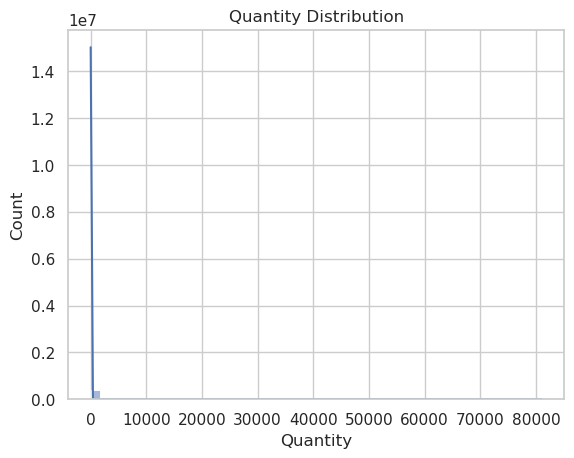

In [35]:
sns.histplot(df["Quantity"], bins=50, kde=True)
plt.title("Quantity Distribution")
plt.show()

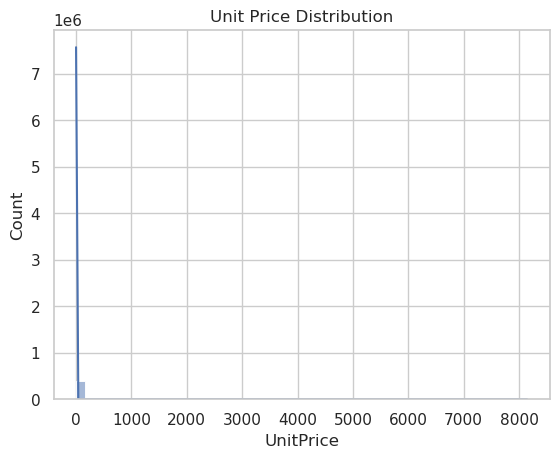

In [31]:
sns.histplot(df["UnitPrice"], bins=50, kde=True)
plt.title("Unit Price Distribution")
plt.show()

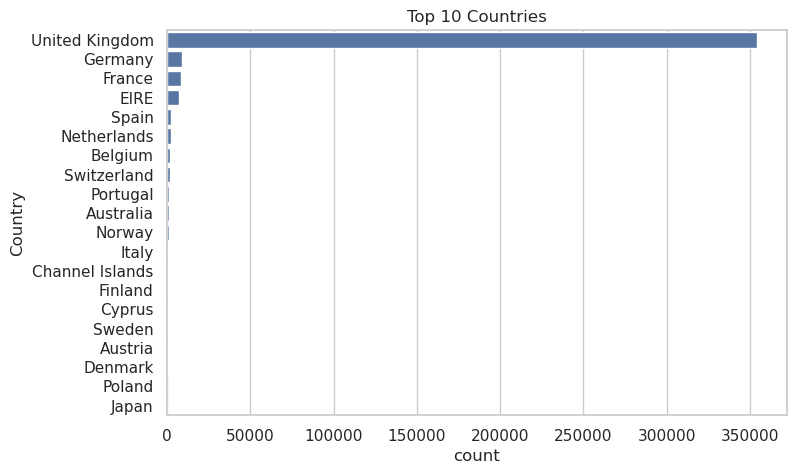

In [27]:
plt.figure(figsize=(8,5))
sns.countplot(y="Country", data=df, order=df["Country"].value_counts().index[:20])
plt.title("Top 10 Countries")
plt.show()

In [8]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalPrice": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


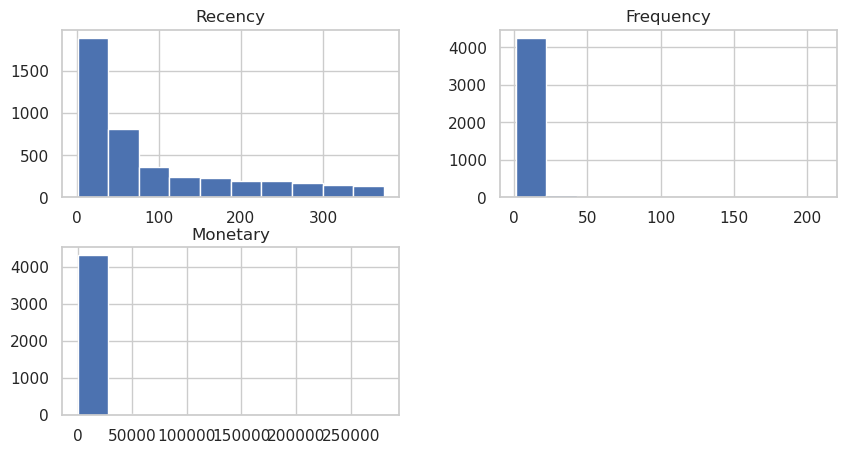

In [9]:
rfm.hist(figsize=(10,5))
plt.show()

In [10]:
rfm_log = np.log1p(rfm)

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

## CLUSTERING

### Modeling

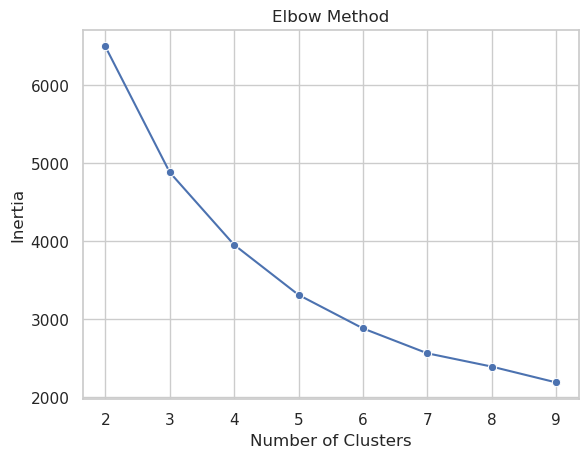

In [12]:
inertia = []

for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

sns.lineplot(x=range(2,10), y=inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

In [13]:
kmeans = KMeans(n_clusters=4, random_state=42)
labels = kmeans.fit_predict(X_scaled)

rfm["Cluster"] = labels

In [14]:
silhouette_score(X_scaled, labels)

0.33627437675322647

### Interpretation

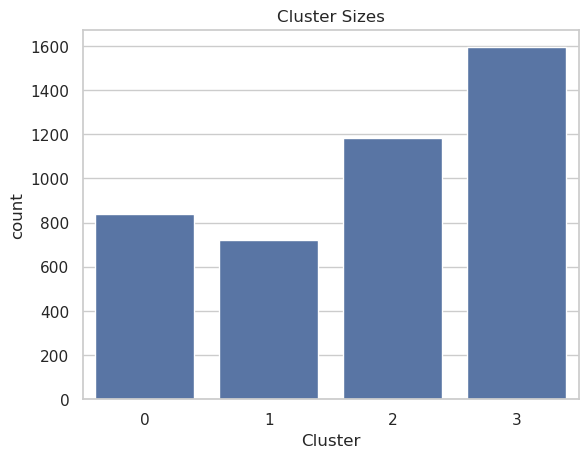

In [15]:
sns.countplot(x="Cluster", data=rfm)
plt.title("Cluster Sizes")
plt.show()

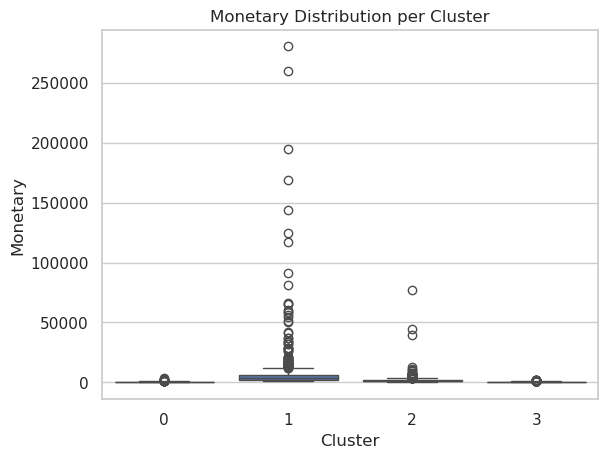

In [16]:
sns.boxplot(x="Cluster", y="Monetary", data=rfm)
plt.title("Monetary Distribution per Cluster")
plt.show()

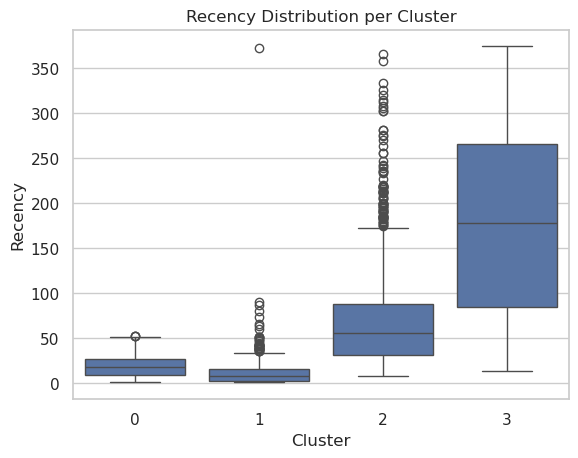

In [17]:
sns.boxplot(x="Cluster", y="Recency", data=rfm)
plt.title("Recency Distribution per Cluster")
plt.show()

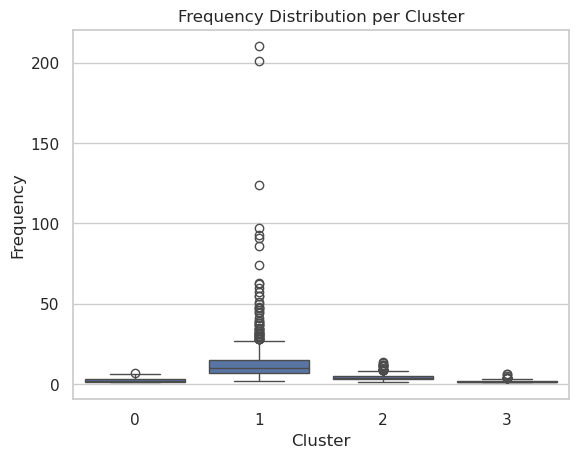

In [18]:
sns.boxplot(x="Cluster", y="Frequency", data=rfm)
plt.title("Frequency Distribution per Cluster")
plt.show()

In [19]:
cluster_profile = rfm.groupby("Cluster").mean()
print(cluster_profile)

            Recency  Frequency     Monetary
Cluster                                    
0         18.725864   2.090584   538.231287
1         12.112033  13.634855  8015.424412
2         70.697380   4.076923  1791.090873
3        184.023839   1.318068   342.421268


### Dimensionality reduction

#### PCA

In [20]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Cluster"] = labels

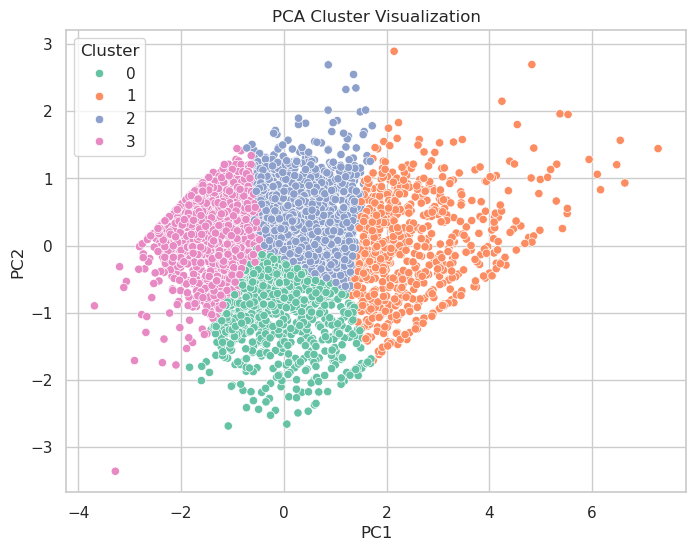

In [21]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    data=pca_df
)
plt.title("PCA Cluster Visualization")
plt.show()

#### t-SNE

In [22]:
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

tsne_df = pd.DataFrame(X_tsne, columns=["Dim1", "Dim2"])
tsne_df["Cluster"] = labels

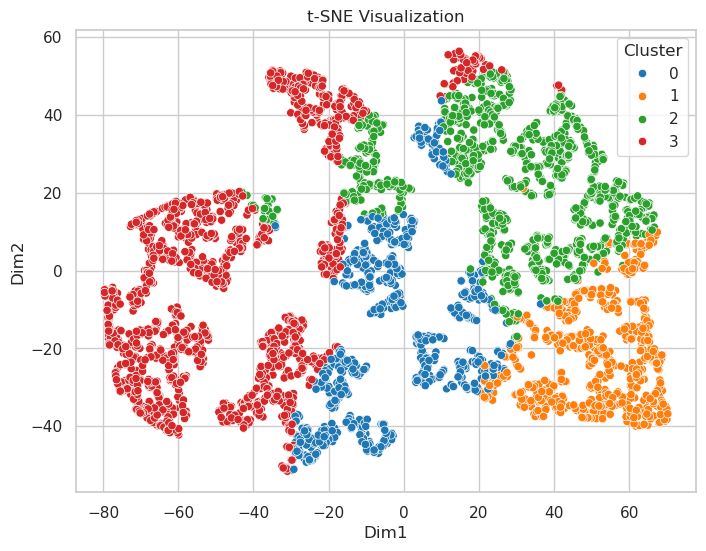

In [23]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    x="Dim1",
    y="Dim2",
    hue="Cluster",
    palette="tab10",
    data=tsne_df
)
plt.title("t-SNE Visualization")
plt.show()

#### DBSCAN

In [24]:
db = DBSCAN(eps=0.8, min_samples=5)
db_labels = db.fit_predict(X_scaled)

rfm["DBSCAN_Cluster"] = db_labels

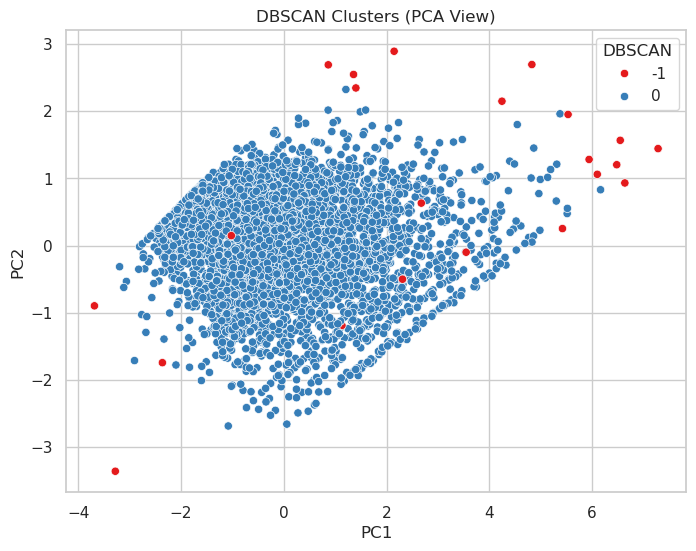

In [25]:
pca_df["DBSCAN"] = db_labels

plt.figure(figsize=(8,6))
sns.scatterplot(
    x="PC1",
    y="PC2",
    hue="DBSCAN",
    palette="Set1",
    data=pca_df
)
plt.title("DBSCAN Clusters (PCA View)")
plt.show()